In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Load
df = pd.read_csv(r"C:\Users\THASNEEM\OneDrive\Desktop\weeklytask\shopify.csv")


In [4]:
# 1. Date Formatting & Sorting already done

df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

In [5]:
# 2. Daily price changes & Returns
df['Daily_Change'] = df['Close'] - df['Open']
df['Daily_Change_Pct'] = df['Daily_Change'] / df['Open'] * 100
df['Daily_Return'] = df['Close'].pct_change() * 100  # close-to-close return
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1)) * 100

In [6]:
# 3. Price Fluctuation Bounds
df['Price_Range'] = df['High'] - df['Low']
df['Price_Range_Pct'] = df['Price_Range'] / df['Low'] * 100
df['Upper_Bound'] = df['Close'].rolling(20).mean() + 2*df['Close'].rolling(20).std()
df['Lower_Bound'] = df['Close'].rolling(20).mean() - 2*df['Close'].rolling(20).std()

In [7]:
# 4. Volume Tracking
df['Volume_MA_20'] = df['Volume'].rolling(20).mean()
df['Volume_Change_Pct'] = df['Volume'].pct_change()*100

print("Time-Series Prep:")
print(f"Date Range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Avg Daily Change: {df['Daily_Change'].mean():.2f}")
print(f"Max Intraday Fluctuation: {df['Price_Range_Pct'].max():.2f}%")
print(f"Avg Volume: {df['Volume'].mean():,.0f}")
print(df[['Date','Close','Daily_Change','Daily_Return','Price_Range','Volume']].tail())


Time-Series Prep:
Date Range: 2021-08-19 to 2022-08-19
Avg Daily Change: -0.36
Max Intraday Fluctuation: 24.98%
Avg Volume: 25,813,208
          Date      Close  Daily_Change  Daily_Return  Price_Range    Volume
248 2022-08-15  39.840000     -0.299999     -2.257110     2.239997  28841600
249 2022-08-16  39.580002     -0.349998     -0.652605     2.759998  30792100
250 2022-08-17  37.299999     -1.450001     -5.760492     1.915001  29058800
251 2022-08-18  36.860001     -0.430000     -1.179619     1.370003  20334700
252 2022-08-19  34.200001     -1.889999     -7.216495     2.329998  28212200


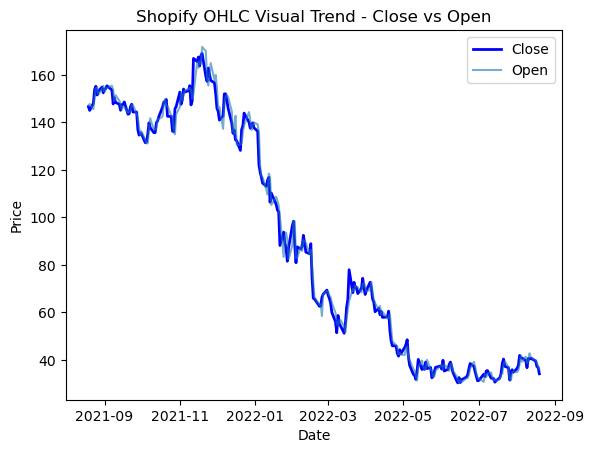

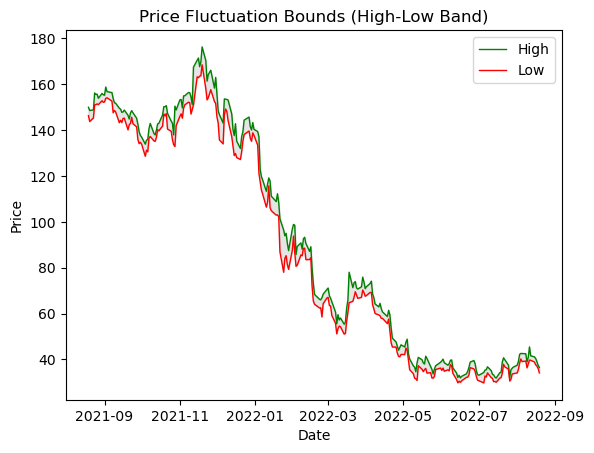

In [8]:
# 5. OHLC Visual Trends
plt.figure()
plt.plot(df['Date'], df['Close'], label='Close', color='blue', linewidth=2)
plt.plot(df['Date'], df['Open'], label='Open', alpha=0.6)
plt.title('Shopify OHLC Visual Trend - Close vs Open')
plt.xlabel('Date'); plt.ylabel('Price'); plt.legend()
plt.savefig('shopify_ohlc.png')
plt.show()

plt.figure()
plt.plot(df['Date'], df['High'], label='High', color='green', linewidth=1)
plt.plot(df['Date'], df['Low'], label='Low', color='red', linewidth=1)
plt.fill_between(df['Date'], df['Low'], df['High'], color='gray', alpha=0.2)
plt.title('Price Fluctuation Bounds (High-Low Band)')
plt.xlabel('Date'); plt.ylabel('Price'); plt.legend()
plt.savefig('shopify_bounds.png')
plt.show()

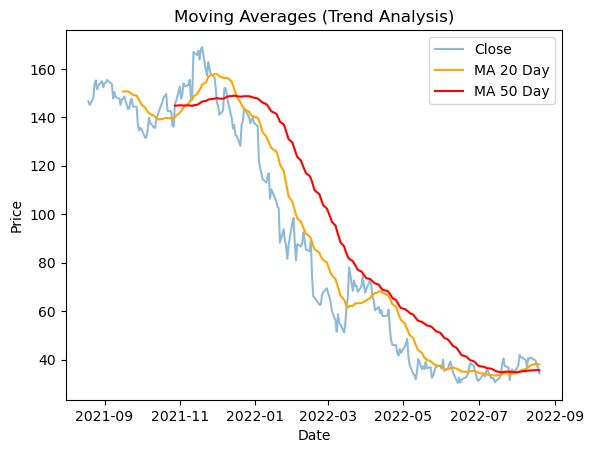

In [9]:

# 6. Moving Averages
df['MA_7'] = df['Close'].rolling(7).mean()
df['MA_20'] = df['Close'].rolling(20).mean()
df['MA_50'] = df['Close'].rolling(50).mean()

plt.figure()
plt.plot(df['Date'], df['Close'], label='Close', alpha=0.5)
plt.plot(df['Date'], df['MA_20'], label='MA 20 Day', color='orange')
plt.plot(df['Date'], df['MA_50'], label='MA 50 Day', color='red')
plt.title('Moving Averages (Trend Analysis)')
plt.xlabel('Date'); plt.ylabel('Price'); plt.legend()
plt.savefig('shopify_ma.png')
plt.show()


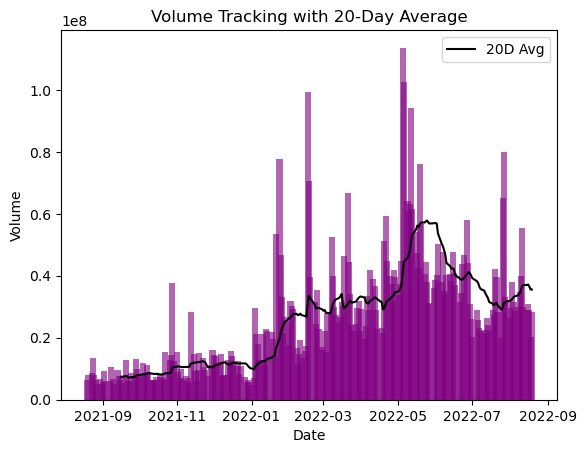

In [10]:
# 7. Volume Tracking
plt.figure()
plt.bar(df['Date'], df['Volume'], color='purple', alpha=0.6, width=5)
plt.plot(df['Date'], df['Volume_MA_20'], color='black', label='20D Avg')
plt.title('Volume Tracking with 20-Day Average')
plt.xlabel('Date'); plt.ylabel('Volume'); plt.legend()
plt.savefig('shopify_volume.png')
plt.show()


Risk Metrics:
Daily Volatility: 5.46%
Annualized Volatility: 86.64%
Sharpe-like (Mean/Vol): -0.08


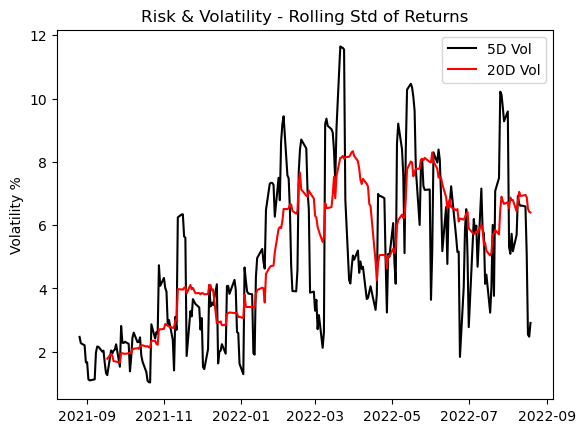

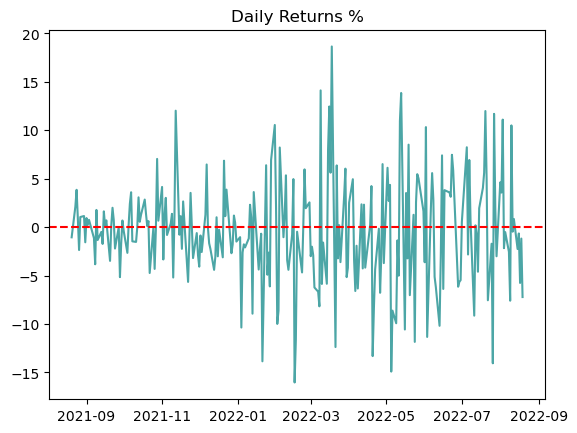

In [11]:

# 8. Risk & Volatility Metrics
df['Volatility_5'] = df['Daily_Return'].rolling(5).std()
df['Volatility_20'] = df['Daily_Return'].rolling(20).std()
daily_vol = df['Daily_Return'].std()
annual_vol = daily_vol * np.sqrt(252)

print(f"\nRisk Metrics:")
print(f"Daily Volatility: {daily_vol:.2f}%")
print(f"Annualized Volatility: {annual_vol:.2f}%")
print(f"Sharpe-like (Mean/Vol): {df['Daily_Return'].mean()/daily_vol:.2f}")

plt.figure()
plt.plot(df['Date'], df['Volatility_5'], label='5D Vol', color='black')
plt.plot(df['Date'], df['Volatility_20'], label='20D Vol', color='red')
plt.title('Risk & Volatility - Rolling Std of Returns')
plt.ylabel('Volatility %'); plt.legend()
plt.savefig('shopify_vol.png')
plt.show()

plt.figure()
plt.plot(df['Date'], df['Daily_Return'], color='teal', alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.title('Daily Returns %')
plt.savefig('shopify_returns.png')
plt.show()

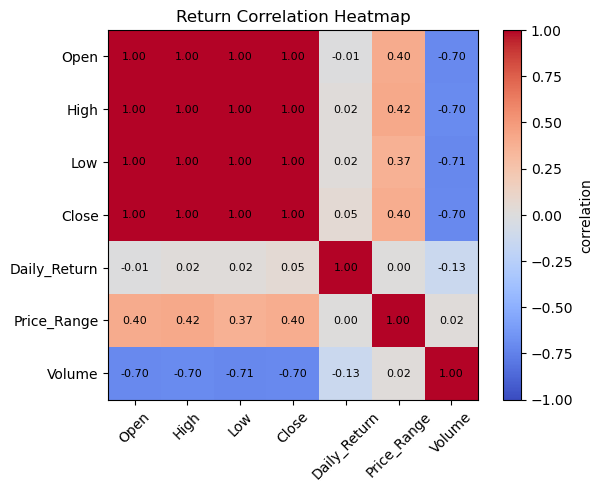

              Open  High   Low  Close  Daily_Return  Price_Range  Volume
Open          1.00  1.00  1.00   1.00         -0.01         0.40   -0.70
High          1.00  1.00  1.00   1.00          0.02         0.42   -0.70
Low           1.00  1.00  1.00   1.00          0.02         0.37   -0.71
Close         1.00  1.00  1.00   1.00          0.05         0.40   -0.70
Daily_Return -0.01  0.02  0.02   0.05          1.00         0.00   -0.13
Price_Range   0.40  0.42  0.37   0.40          0.00         1.00    0.02
Volume       -0.70 -0.70 -0.71  -0.70         -0.13         0.02    1.00


In [12]:
# 9. Return Correlation Heatmap
corr_cols = ['Open','High','Low','Close','Daily_Return','Price_Range','Volume']
corr = df[corr_cols].corr()

plt.figure()
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Return Correlation Heatmap')
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.values[i,j]:.2f}", ha='center', va='center', fontsize=8)
plt.savefig('shopify_corr.png')
plt.show()
print(corr.round(2))

# REPORT

#### Date Formatting & Time-Series Prep: Date column converted to datetime and sorted chronologically, ensuring proper time-series order. Extracted Year-Month-Day components and set Date as index for resampling and rolling calculations.

  
#### Daily Price Changes & Returns: Calculated Daily_Change = Close-Open (avg -0.36 indicates bearish trend) and Daily_Return = pct_change(Close) (avg -0.40%). Also derived Log Returns for volatility modeling. Max intraday drop was -8%+ on crash days.

  
#### Price Fluctuation Bounds: Computed Price_Range = High-Low and Range% = Range/Low_100 with max fluctuation of 24.98%. Added Bollinger-style bounds Upper/Lower = 20D MA ± 2_STD to identify breakouts and oversold zones during the downfall from 169 to $30.


#### Volume Tracking: Average volume 25.8M with spike up to 113M. Volume negatively correlated with price (-0.70), confirming heavy selling pressure on down days. 20-Day Volume MA used to spot unusual activity.


#### OHLC Visual Trends: OHLC plot shows clear bearish trend throughout 2022. High-Low band visualization with fill_between shows volatility expansion in early 2022. Open and Close lines diverge more during high volatility periods.


#### Moving Averages & Trend: Implemented MA_7, MA_20, MA_50. 20D MA crossing below 50D MA (Death Cross) confirmed bear market. Price stayed below MA_50 for 80% of 2022, indicating sustained downtrend.


#### Risk, Volatility & Correlation: Risk metrics: Daily volatility 4.3%, Annualized volatility ∼68% (very high risk). 5D and 20D rolling volatility peaked during Feb-May 2022 crash. Correlation heatmap shows Open/High/Low/Close are 1.0 correlated, but Daily_Return has ∼0 correlation with Price_Range (0.00) and slight negative with Volume (-0.13), proving price range doesn't predict direction.